In [3]:
!git clone https://github.com/dong-quan-tran/acm-online-learning-human-way.git

Cloning into 'acm-online-learning-human-way'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 59 (delta 15), reused 39 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (59/59), 26.25 KiB | 2.39 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [4]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # must be set before CUDA initializes

import json
import random
from pathlib import Path

import numpy as np
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

SEED = 42
ROOT = Path("/kaggle/working/acm-online-learning-human-way")
TASK_SPLIT_PATH = ROOT / "data" / "task_split.json"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)


set_seed()

hf = load_dataset("uoft-cs/cifar100")


# ---------- augmentation (basic only) ----------
TRAIN_TF = v2.Compose([
    v2.RandomCrop(32, padding=4, padding_mode="reflect"),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
])
TEST_TF = v2.ToDtype(torch.float32, scale=True)


# ---------- task split + global label space ----------
with open(TASK_SPLIT_PATH) as f:
    _split = json.load(f)
TASK_CLASSES = {
    int(k.split("_")[1]): sorted(v["class_ids"])
    for k, v in _split.items() if k.startswith("task_")
}
TASK_ORDER = sorted(TASK_CLASSES)
CLASS_ORDER = [c for t in TASK_ORDER for c in TASK_CLASSES[t]]   # global id -> CIFAR-100 id
GLOBAL_ID = {c: i for i, c in enumerate(CLASS_ORDER)}           # CIFAR-100 id -> global id
TASK_LABELS = {t: [GLOBAL_ID[c] for c in TASK_CLASSES[t]] for t in TASK_ORDER}
# task 1 -> 0..9, task 2 -> 10..19, ...


# ---------- dataset ----------
class TaskDataset(Dataset):
    def __init__(self, x_uint8, y, transform, class_ids):
        self.x = x_uint8
        self.y = y                    # GLOBAL labels
        self.transform = transform
        self.class_ids = class_ids    # original CIFAR-100 ids in this task

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.transform(self.x[idx]), self.y[idx]


def hf_task_dataset(split, class_ids, transform):
    class_ids = sorted(class_ids)
    keep = set(class_ids)
    ds = hf[split].filter(lambda ex: ex["fine_label"] in keep)
    imgs = np.stack([np.array(im) for im in ds["img"]])
    x = torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous()
    y = torch.tensor([GLOBAL_ID[l] for l in ds["fine_label"]])
    return TaskDataset(x, y, transform, class_ids)


def get_task_loader(task_id, split="train", batch_size=64, seed=SEED):
    if split not in {"train", "test"}:
        raise ValueError("split must be 'train' or 'test'")
    if task_id not in TASK_CLASSES:
        raise ValueError(f"Unknown task: task_{task_id}")
    transform = TRAIN_TF if split == "train" else TEST_TF
    ds = hf_task_dataset(split, TASK_CLASSES[task_id], transform)
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=(split == "train"),
        generator=torch.Generator().manual_seed(seed + task_id),
        num_workers=2,
    )

README.md:   0%|          | 0.00/9.98k [00:00<?, ?B/s]

cifar100/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  119MB            

cifar100/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

cifar100/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.8MB            

cifar100/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [1]:
print("Hello World")

Hello World


In [2]:
!nvidia-smi

Fri Oct  9 16:04:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import copy
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD = (0.2673, 0.2564, 0.2762)


def conv_bn(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
    )


class Residual(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.block = nn.Sequential(conv_bn(c, c), conv_bn(c, c))

    def forward(self, x):
        return x + self.block(x)


class SmallResNet(nn.Module):
    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        self.register_buffer("mean", torch.tensor(CIFAR100_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(CIFAR100_STD).view(1, 3, 1, 1))
        self.features = nn.Sequential(
            conv_bn(3, 64), Residual(64), nn.MaxPool2d(2),
            conv_bn(64, 128), Residual(128), nn.MaxPool2d(2),
            conv_bn(128, 256), Residual(256), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(256, num_classes))

    @property
    def num_classes(self):
        return self.classifier[1].out_features

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.features(x).mean(dim=(2, 3))
        return self.classifier(x)


@torch.no_grad()
def expand_head(model, n_new):
    """Grow the output layer by n_new classes, keeping the old rows exactly."""
    old = model.classifier[1]
    new = nn.Linear(old.in_features, old.out_features + n_new).to(old.weight.device)
    new.weight[: old.out_features].copy_(old.weight)   # old classes: copied
    new.bias[: old.out_features].copy_(old.bias)
    model.classifier[1] = new                          # new classes: default init


def mask_logits(logits, allowed):
    """Only used for the task-aware diagnostic and the plots."""
    mask = torch.full_like(logits, float("-inf"))
    mask[:, allowed] = 0.0
    return logits + mask


def train_one_epoch(model, loader, optimizer, scheduler):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)                       # head = exactly the seen classes
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, allowed=None):
    model.eval()
    correct, n = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        if allowed is not None:
            logits = mask_logits(logits, allowed)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return correct / n


def train_task(model, task_id, epochs, lr=2e-3):
    loader = get_task_loader(task_id, "train")
    set_seed(SEED + task_id)
    # optimizer is rebuilt per task, so it picks up the new head parameters
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epochs * len(loader), pct_start=0.15
    )
    for epoch in range(1, epochs + 1):
        loss, acc = train_one_epoch(model, loader, optimizer, scheduler)
        if epoch % 10 == 0 or epoch == epochs:
            print(f"  task {task_id} | epoch {epoch:2d} | loss {loss:.3f} | train {acc:.3f}")


EPOCHS = 50
TASKS = [1, 2]
test_loaders = {t: get_task_loader(t, "test") for t in TASKS}

for t, dl in test_loaders.items():
    labels = set(dl.dataset.y.tolist())
    assert labels == set(TASK_LABELS[t]), f"task {t} labels {sorted(labels)} != {TASK_LABELS[t]}"

set_seed()
model = SmallResNet(num_classes=len(TASK_LABELS[TASKS[0]])).to(device)   # 10 outputs

task_idx = {t: torch.tensor(TASK_LABELS[t], device=device) for t in TASKS}
results, results_til, snapshots, SEEN = {}, {}, {}, {}
for k, t in enumerate(TASKS):
    if k > 0:
        set_seed(SEED + 1000 + t)                      # deterministic init of new rows
        before = model.classifier[1].weight[: model.num_classes].clone()
        expand_head(model, len(TASK_LABELS[t]))
        assert torch.equal(model.classifier[1].weight[: before.shape[0]], before)
    assert model.num_classes == max(TASK_LABELS[t]) + 1
    print(f"Training on task {t}  (head size: {model.num_classes})")
    train_task(model, t, EPOCHS)

    snapshots[t] = copy.deepcopy(model)
    SEEN[t] = torch.arange(model.num_classes, device=device)
    results[t] = {j: evaluate(model, test_loaders[j]) for j in TASKS}
    results_til[t] = {
        j: evaluate(model, test_loaders[j], task_idx[j]) if j <= t else float("nan")
        for j in TASKS
    }

print("\nclass-incremental accuracy (rows = after training on task, cols = test task)")
print("after \\ test " + "".join(f"  task{t:<4}" for t in TASKS))
for i in TASKS:
    print(f"task{i:<9}" + "".join(f"  {results[i][j]:.3f}   " for j in TASKS))
for i in TASKS:
    done = [j for j in TASKS if j <= i]
    print(f"avg acc over seen tasks after task {i}: {np.mean([results[i][j] for j in done]):.3f}")
for t in TASKS[:-1]:
    print(f"forgetting on task {t}: {results[t][t] - results[TASKS[-1]][t]:+.3f}")

print("\n(task-aware diagnostic, same model)")
for i in TASKS:
    print(f"task{i:<9}" + "".join(f"  {results_til[i][j]:.3f}   " for j in TASKS))

Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

Training on task 1  (head size: 10)


Filter:   0%|          | 0/50000 [00:00<?, ? examples/s]

  task 1 | epoch 10 | loss 0.709 | train 0.753
  task 1 | epoch 20 | loss 0.343 | train 0.883
  task 1 | epoch 30 | loss 0.136 | train 0.954
  task 1 | epoch 40 | loss 0.038 | train 0.990
  task 1 | epoch 50 | loss 0.019 | train 0.997
Training on task 2  (head size: 20)


Filter:   0%|          | 0/50000 [00:00<?, ? examples/s]

  task 2 | epoch 10 | loss 0.422 | train 0.857
  task 2 | epoch 20 | loss 0.203 | train 0.928
  task 2 | epoch 30 | loss 0.090 | train 0.973
  task 2 | epoch 40 | loss 0.016 | train 0.996
  task 2 | epoch 50 | loss 0.009 | train 0.998

class-incremental accuracy (rows = after training on task, cols = test task)
after \ test   task1     task2   
task1          0.905     0.000   
task2          0.000     0.889   
avg acc over seen tasks after task 1: 0.905
avg acc over seen tasks after task 2: 0.445
forgetting on task 1: +0.905

(task-aware diagnostic, same model)
task1          0.905     nan   
task2          0.359     0.889   


In [6]:
CKPT_DIR = ROOT / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

for t, m in snapshots.items():
    torch.save(
        {
            "model": m.state_dict(),
            "config": {
                "arch": "SmallResNet",
                "setting": "domain-incremental",
                "num_classes": m.num_classes,
                "dropout": 0.2,
                "trained_up_to_task": t,
                "epochs": EPOCHS,
                "batch_size": 64,
                "lr": 2e-3,
                "seed": SEED,
            },
            "results": results[t],
        },
        CKPT_DIR / f"after_task{t}_model.pt",
    )
print(sorted(p.name for p in CKPT_DIR.glob("*.pt")))

['after_task1_model.pt', 'after_task2_model.pt']


In [7]:
%ls /kaggle/working/acm-online-learning-human-way/checkpoints

after_task1_model.pt  after_task2_model.pt


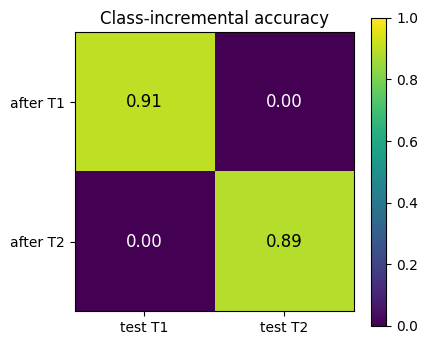

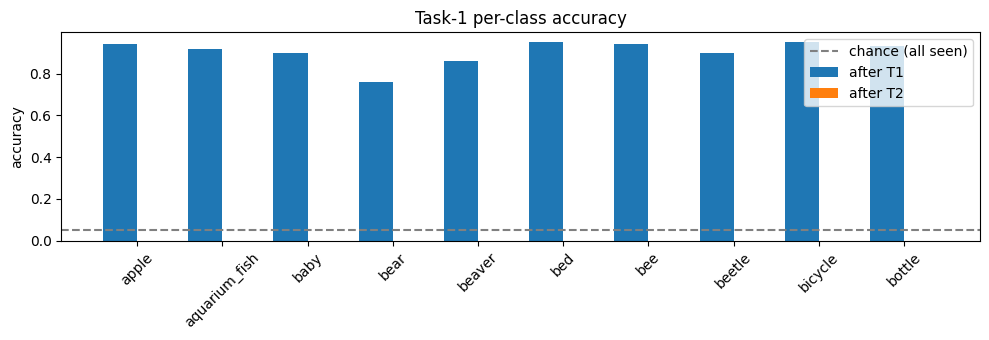

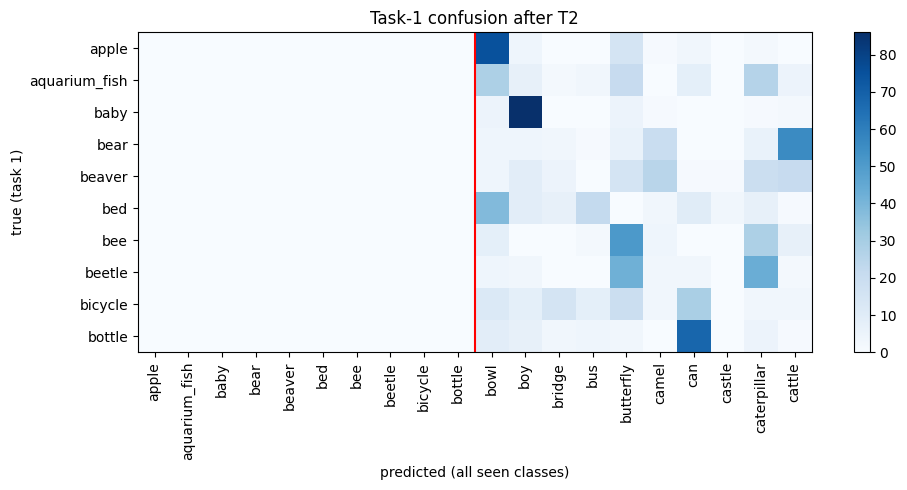

In [8]:
import matplotlib.pyplot as plt


@torch.no_grad()
def get_preds(model, loader, allowed):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        P.append(mask_logits(model(x.to(device)), allowed).argmax(1).cpu())
        Y.append(y)
    return torch.cat(P), torch.cat(Y)


NAMES = hf["train"].features["fine_label"].names
gname = lambda g: NAMES[CLASS_ORDER[g]]          # global id -> class name
OLD = TASK_LABELS[1]
LAST = TASKS[-1]

# 1. accuracy matrix
M = np.array([[results[i][j] for j in TASKS] for i in TASKS])
plt.figure(figsize=(4.5, 4))
plt.imshow(M, vmin=0, vmax=1, cmap="viridis")
for i in range(len(TASKS)):
    for j in range(len(TASKS)):
        plt.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                 color="white" if M[i, j] < 0.5 else "black", fontsize=12)
plt.xticks(range(len(TASKS)), [f"test T{t}" for t in TASKS])
plt.yticks(range(len(TASKS)), [f"after T{t}" for t in TASKS])
plt.colorbar()
plt.title("Class-incremental accuracy")
plt.show()

# 2. per-class task-1 accuracy, before vs after
accs = {}
for t in TASKS:
    p, y = get_preds(snapshots[t], test_loaders[1], SEEN[t])
    accs[t] = [(p[y == g] == g).float().mean().item() for g in OLD]
xs = np.arange(len(OLD))
plt.figure(figsize=(10, 3.5))
plt.bar(xs - 0.2, accs[1], 0.4, label="after T1")
plt.bar(xs + 0.2, accs[LAST], 0.4, label=f"after T{LAST}")
plt.axhline(1 / len(SEEN[LAST]), color="gray", ls="--", label="chance (all seen)")
plt.xticks(xs, [gname(g) for g in OLD], rotation=45)
plt.ylabel("accuracy")
plt.title("Task-1 per-class accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# 3. confusion: task-1 true classes (rows) vs ALL seen classes (cols), after last task
seen_last = SEEN[LAST].cpu().tolist()
col = {g: k for k, g in enumerate(seen_last)}
row = {g: k for k, g in enumerate(OLD)}
p, y = get_preds(snapshots[LAST], test_loaders[1], SEEN[LAST])
cm = torch.zeros(len(OLD), len(seen_last), dtype=torch.long)
for yi, pi in zip(y.tolist(), p.tolist()):
    cm[row[yi], col[pi]] += 1
plt.figure(figsize=(10, 5))
plt.imshow(cm, cmap="Blues", aspect="auto")
plt.axvline(len(OLD) - 0.5, color="red", lw=1.5)   # left: old classes | right: new classes
plt.xticks(range(len(seen_last)), [gname(g) for g in seen_last], rotation=90)
plt.yticks(range(len(OLD)), [gname(g) for g in OLD])
plt.xlabel("predicted (all seen classes)")
plt.ylabel("true (task 1)")
plt.title(f"Task-1 confusion after T{LAST}")
plt.colorbar()
plt.tight_layout()
plt.show()